In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:85% !important; }</style>"))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from cosmoblender import tools as tls
from cosmoblender import qest
from cosmoblender import biases
import os

/var/folders/zf/xwwhf0ps6yx93zy9ttqm3mm80000gn/T/ipykernel_63302/3607683207.py:5: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML


IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/mpi.py (No module named 'pypar'). Could not load pbs or pypar. MPI will not be used.
IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/shts/__init__.py (No module named 'fsht'). Try running 'python setup.py install' or 'python setup.py build_ext --inplace' from the quicklens directory.


In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/3 #8.77 #inches

# Decide whether or not to break down the total into contributions from different halos
plot_breakdown = True

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)
plots_dir = '/Users/antonbaleatolizancos/Projects/lensing_rec_biases/paper/5f71fb65ea173d000120afc7/'

# Hacky way of typsetting scientific notation
def as_si(x, ndp):
    '''
    From https://stackoverflow.com/questions/31453422/displaying-numbers-with-x-instead-of-e-scientific-notation-in-matplotlib/31453961
    - Inputs:
        * x = number
        * ndp = number of decimal places
    '''
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

Initialise experiment object

In [3]:
# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = True 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}

In [4]:
SO_properties = {'nlev_t': np.array([52., 27., 5.8, 6.3, 15., 37.]),
                 'beam_size':np.array([7.4, 5.1, 2.2, 1.4, 1.0, 0.9]),
                 'freq_GHz': np.array([27.3, 41.7, 93., 143., 225.,278.])}

ACT_properties = {'nlev_t': np.array([15., 15.]),
                 'beam_size':np.array([2.1, 1.4]),
                 'freq_GHz': np.array([90., 150.])}

SO_single_freq_properties = {'nlev_t': np.array([5.8]),
                 'beam_size':np.array([2.2]),
                 'freq_GHz': np.array([143])}

# Initialise experiments with various different mass cuts
SO_single_freq = qest.experiment(lmax = 4000, massCut_Mvir=1e14, **SO_single_freq_properties, **fg_cleaning_dict)
ACT = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

In [5]:
# Choose an experiment
experiment = ACT

One can later inspect the properties by doing

In [ ]:
print(experiment)

Mass Cut: 2.00e+14  lmax: 3000  Beam FWHM: [2.1 1.4] Noise (uK arcmin): [15. 15.]  Freq (GHz): [ 90. 150.]


Initialise halo model calculator

In [ ]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

z_max = 2
nZs = 50
nMasses = 80 
Mmin = 1e9 #Keep this low -- the 2h term of the bispectrum bias can be sensitive to quite low-mass halos

# Set CIB halo model
cib_model='planck13'#'vierro'

# Initialise a halo model object for the calculation, using mostly default parameters
hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

ells = np.linspace(2, hm_calc.lmax_out, 50)

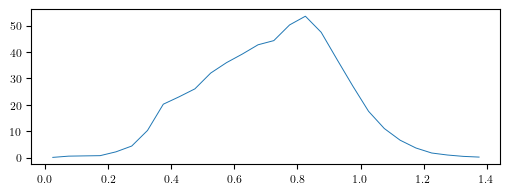

In [8]:
survey_name = "DESI LRG"

# Add the HOD for the galaxy sample that we will be cross-correlating with CMB lensing
z_mean_gal, surface_ngal_of_z_gal = tls.get_DESI_surface_ngal_of_z('lrg')
plt.plot(z_mean_gal, surface_ngal_of_z_gal)

# Assume a sample that's 100% complete above a stellar mass threshold of 10^11.5 Msun
hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

# Calculate the signal clkg
pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
Pgm = pgm_1h + pgm_2h
ells = np.linspace(2, hm_calc.lmax_out, 50)
Cls = hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, Pgm, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.)

# Calculate biases to cross-correlations with galaxies

In [9]:
which_bias = 'total' # 'total' or 'tsz' or 'cib' or 'mixed'

if which_bias=='total' or which_bias=='tsz':
    hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
if which_bias=='total' or which_bias=='cib':
    hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
if which_bias=='total' or which_bias=='mixed':
    hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)

Platform 'METAL' is experimental and not all JAX functionality may be correctly supported!
W0000 00:00:1772131214.376776 7207374 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1772131214.392745 7207374 service.cc:145] XLA service 0x12ae618b0 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772131214.392774 7207374 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1772131214.394264 7207374 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1772131214.394277 7207374 mps_client.cc:384] XLA backend will use up to 22906109952 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M2 Max

systemMemory: 32.00 GB
maxCacheSize: 10.67 GB



Text(0.5, 1.0, 'Bias from total')

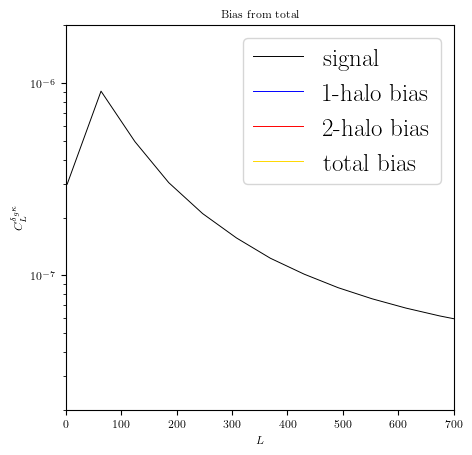

In [10]:
# Split into negative and positive parts for plotting convenience
cross_w_gals_1h_pos, cross_w_gals_1h_neg = tls.split_positive_negative(experiment.biases[which_bias]['cross_w_gals']['1h'])
cross_w_gals_2h_pos, cross_w_gals_2h_neg = tls.split_positive_negative(experiment.biases[which_bias]['cross_w_gals']['2h'])
cross_w_gals_tot_pos, cross_w_gals_tot_neg = tls.split_positive_negative(experiment.biases[which_bias]['cross_w_gals']['1h'] + 
                                                                         experiment.biases[which_bias]['cross_w_gals']['2h'])

plt.figure(figsize=(5, 5))
scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)

plt.plot(ells, Cls, 'k', label=r'signal')

plt.plot(experiment.biases['ells'], scaling * cross_w_gals_1h_pos, color='b', label='1-halo bias')
plt.plot(experiment.biases['ells'], scaling * cross_w_gals_1h_neg, color='b', ls='--')

plt.plot(experiment.biases['ells'], scaling * cross_w_gals_2h_pos, color='r', label='2-halo bias')
plt.plot(experiment.biases['ells'], scaling * cross_w_gals_2h_neg, color='r', ls='--')

plt.plot(experiment.biases['ells'], scaling * cross_w_gals_tot_pos, color='gold', label='total bias')
plt.plot(experiment.biases['ells'], scaling * cross_w_gals_tot_neg, color='gold', ls='--')


plt.yscale('log')
plt.xlim([0, 700])
plt.ylim([2e-8, 2e-6])
ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=8)
ax.tick_params(axis='both', which='minor', labelsize=8)
plt.ylabel(r'$C_{L}^{\delta_{g}\kappa}$')
plt.xlabel(r'$L$')
plt.legend()
plt.title('Bias from {}'.format(which_bias))

# Plot as a function of maximum mass


In [11]:
Mcuts = [1e14, 2e14, 5e14, 1e15]

which_bias='total'
exp_list = []
for Mcut in Mcuts:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=Mcut, **ACT_properties, **fg_cleaning_dict)
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 


    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

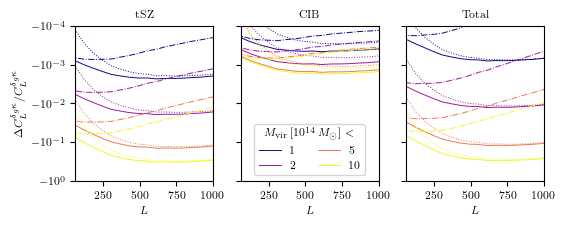

In [ ]:
# Get four colors from the plasma colormap
import matplotlib.cm as cm
colors = cm.plasma(np.linspace(0, 1, len(Mcuts)))

ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

Mcuts = [1e14, 2e14, 5e14, 1e15]

for color, experiment, Mcut in zip(colors, exp_list, Mcuts):
    for j, foreground in enumerate(['tsz', 'cib', 'total']):
        if foreground == 'cib':
            X_factor = 1
        else:
            X_factor = 1
        
        axes[j].set_title([r'tSZ', r'CIB',r'Total'][j])
        axes[j].axhline(0, color='k', lw=0.5, ls='-')
        axes[j].set_xlabel(r'$L$')

        scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)
        total = np.zeros(ells.shape, dtype='complex128')

        for linestyle, term in zip([':','-.', '-'], ['1h', '2h','total']):
            if term == 'total':
                if j==1:
                    label = r'{}'.format(int(Mcut/1e14))
                else:
                    label = None
                axes[j].plot(ells, X_factor * ((scaling * total+Cls)/Cls - 1), color=color, ls=linestyle, label=label)
            else:
                # Extract contribution from this-halo term
                bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                # Accumulate to later plot the total
                total += bias_contribution                
                if plot_breakdown:
                    suffix='_withbreakdown'
                    axes[j].plot(ells,  X_factor * ((scaling * bias_contribution+Cls)/Cls - 1), color=color, ls=linestyle)
            ax = plt.gca()
            ax.set_yscale('symlog', linthresh=1e-4)



axes[1].legend(title=r'$M_{\rm vir}$\,[$10^{14}\,M_{\odot}$] $<$ ', fontsize=8, title_fontsize=8, loc='lower center', ncols=2)

plt.xlim([60, 1000])
plt.ylim([-1,-1e-4])#plt.ylim([-1.2,1.2])
#fig.tight_layout()

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_cross_vs_Mcut.pdf', bbox_inches='tight', dpi=1000)



# Bias as a function of CMB lmax

In [18]:
lmaxes = [3000, 3500, 4000]

which_bias='total'
exp_list = []
for lmax in lmaxes:
    experiment = qest.experiment(lmax = lmax, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 


    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in parallel loop 12
Now in parallel loop 13
Now in parallel loop 14
Now in parallel loop 15
Now in parallel loop 16
Now in parallel loop 17
Now in parallel loop 18
Now in parallel loop 19
Now in parallel loop 20
Now in parallel loop 21
Now in parallel loop 22
Now in parallel loop 23
Now in parallel loop 24
Now in parallel loop 25
Now in parallel loop 26
Now in parallel loop 27
Now in parallel loop 28
Now in parallel loop 29
Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in paral

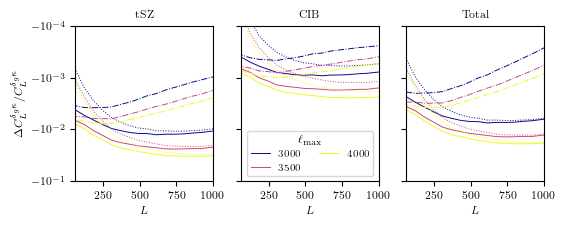

In [ ]:
# Get four colors from the plasma colormap
import matplotlib.cm as cm
colors = cm.plasma(np.linspace(0, 1, len(lmaxes)))

ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

for color, experiment, lmax in zip(colors, exp_list, lmaxes):
    for j, foreground in enumerate(['tsz', 'cib', 'total']):
        if foreground == 'cib':
            X_factor = 1
        else:
            X_factor = 1
        
        axes[j].set_title([r'tSZ', r'CIB',r'Total'][j])
        axes[j].axhline(0, color='k', lw=0.5, ls='-')
        axes[j].set_xlabel(r'$L$')

        scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)
        total = np.zeros(ells.shape, dtype='complex128')

        for linestyle, term in zip([':','-.', '-'], ['1h', '2h','total']):
            if term == 'total':
                if j==1:
                    label = r'{}'.format(int(lmax))
                else:
                    label = None
                axes[j].plot(ells, X_factor * ((scaling * total+Cls)/Cls - 1), color=color, ls=linestyle, label=label)
            else:
                # Extract contribution from this-halo term
                bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                # Accumulate to later plot the total
                total += bias_contribution                
                if plot_breakdown:
                    suffix='_withbreakdown'
                    axes[j].plot(ells,  X_factor * ((scaling * bias_contribution+Cls)/Cls - 1), color=color, ls=linestyle)
            ax = plt.gca()
            ax.set_yscale('symlog', linthresh=1e-4)



axes[1].legend(title=r'$\ell_{\rm max}$', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

plt.xlim([60, 1000])
plt.ylim([-1e-1,-1e-4])#plt.ylim([-1.2,1.2])
#fig.tight_layout()

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_cross_vs_lmax.pdf', bbox_inches='tight', dpi=1000)


# Bias as a function of noise levels

In [28]:
nlev_ts = [7.5, 15., 30.]

which_bias='total'
exp_list = []
for nlev_t in nlev_ts:
    exp_properties = {'nlev_t': np.array([nlev_t, nlev_t]),
                 'beam_size':np.array([2.1, 1.4]),
                 'freq_GHz': np.array([90., 150.])}
    experiment = qest.experiment(lmax = 4000, massCut_Mvir=2e14, **exp_properties, **fg_cleaning_dict)
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 


    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in parallel loop 12
Now in parallel loop 13
Now in parallel loop 14
Now in parallel loop 15
Now in parallel loop 16
Now in parallel loop 17
Now in parallel loop 18
Now in parallel loop 19
Now in parallel loop 20
Now in parallel loop 21
Now in parallel loop 22
Now in parallel loop 23
Now in parallel loop 24
Now in parallel loop 25
Now in parallel loop 26
Now in parallel loop 27
Now in parallel loop 28
Now in parallel loop 29
Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in paral

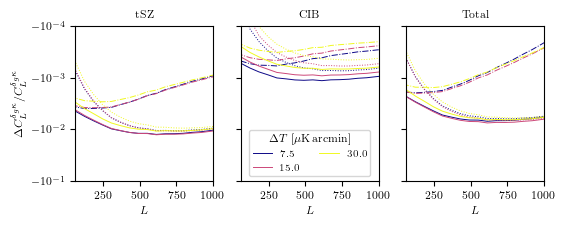

In [ ]:
# Get four colors from the plasma colormap
import matplotlib.cm as cm
colors = cm.plasma(np.linspace(0, 1, len(lmaxes)))

ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

for color, experiment, nlev_t in zip(colors, exp_list, nlev_ts):
    for j, foreground in enumerate(['tsz', 'cib', 'total']):
        if foreground == 'cib':
            X_factor = 1
        else:
            X_factor = 1
        
        axes[j].set_title([r'tSZ', r'CIB',r'Total'][j])
        axes[j].axhline(0, color='k', lw=0.5, ls='-')
        axes[j].set_xlabel(r'$L$')

        scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)
        total = np.zeros(ells.shape, dtype='complex128')

        for linestyle, term in zip([':','-.', '-'], ['1h', '2h','total']):
            if term == 'total':
                if j==1:
                    label = r'{}'.format(float(nlev_t))
                else:
                    label = None
                axes[j].plot(ells, X_factor * ((scaling * total+Cls)/Cls - 1), color=color, ls=linestyle, label=label)
            else:
                # Extract contribution from this-halo term
                bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                # Accumulate to later plot the total
                total += bias_contribution                
                if plot_breakdown:
                    suffix='_withbreakdown'
                    axes[j].plot(ells,  X_factor * ((scaling * bias_contribution+Cls)/Cls - 1), color=color, ls=linestyle)
            ax = plt.gca()
            ax.set_yscale('symlog', linthresh=1e-4)



axes[1].legend(title=r'$\Delta T$ [$\mu\rm{K}\,\rm{arcmin}$]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

plt.xlim([60, 1000])
plt.ylim([-1e-1,-1e-4])#plt.ylim([-1.2,1.2])
#fig.tight_layout()

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_cross_vs_nlev.pdf', bbox_inches='tight', dpi=1000)

In [25]:
beam_factors = [0.1, 0.5, 1.0, 2.0]

which_bias='total'
exp_list = []
for beam_factor in beam_factors:
    exp_properties = {'nlev_t': np.array([15., 15.]),
                 'beam_size':beam_factor*np.array([2.1, 1.4]),
                 'freq_GHz': np.array([90., 150.])}
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **exp_properties, **fg_cleaning_dict)
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 


    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in parallel loop 12
Now in parallel loop 13
Now in parallel loop 14
Now in parallel loop 15
Now in parallel loop 16
Now in parallel loop 17
Now in parallel loop 18
Now in parallel loop 19
Now in parallel loop 20
Now in parallel loop 21
Now in parallel loop 22
Now in parallel loop 23
Now in parallel loop 24
Now in parallel loop 25
Now in parallel loop 26
Now in parallel loop 27
Now in parallel loop 28
Now in parallel loop 29
Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in paral

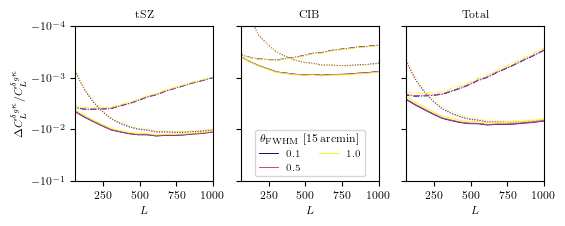

In [ ]:
# Get four colors from the plasma colormap
import matplotlib.cm as cm
colors = cm.plasma(np.linspace(0, 1, len(lmaxes)))

ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

for color, experiment, beam_factor in zip(colors, exp_list, beam_factors):
    for j, foreground in enumerate(['tsz', 'cib', 'total']):
        if foreground == 'cib':
            X_factor = 1
        else:
            X_factor = 1
        
        axes[j].set_title([r'tSZ', r'CIB',r'Total'][j])
        axes[j].axhline(0, color='k', lw=0.5, ls='-')
        axes[j].set_xlabel(r'$L$')

        scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)
        total = np.zeros(ells.shape, dtype='complex128')

        for linestyle, term in zip([':','-.', '-'], ['1h', '2h','total']):
            if term == 'total':
                if j==1:
                    label = r'{}'.format(float(beam_factor))
                else:
                    label = None
                axes[j].plot(ells, X_factor * ((scaling * total+Cls)/Cls - 1), color=color, ls=linestyle, label=label)
            else:
                # Extract contribution from this-halo term
                bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                # Accumulate to later plot the total
                total += bias_contribution                
                if plot_breakdown:
                    suffix='_withbreakdown'
                    axes[j].plot(ells,  X_factor * ((scaling * bias_contribution+Cls)/Cls - 1), color=color, ls=linestyle)
            ax = plt.gca()
            ax.set_yscale('symlog', linthresh=1e-4)



axes[1].legend(title=r'$\theta_{\rm FWHM}$ [15\,arcmin]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

plt.xlim([60, 1000])
plt.ylim([-1e-1,-1e-4])#plt.ylim([-1.2,1.2])
#fig.tight_layout()

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_cross_vs_beam.pdf', bbox_inches='tight', dpi=1000)

# Varying cosmo

In [7]:
As_array = 2.08e-9 * np.linspace(0.5, 1.5, 4)

experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

which_bias='total'
exp_list = []
signal_Cls = []
for As in As_array:
    H0 = 68.
    cosmoParams = {'As':As,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

    # Calculate the signal clkg
    pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
    pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
    signal_Cls.append(hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.))

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

NameError: name 'Mmin' is not defined

(-0.1, -0.0001)

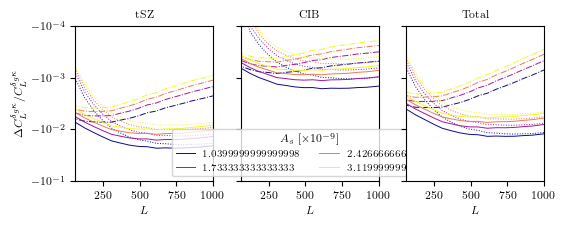

In [ ]:
import matplotlib.cm as cm
colors = cm.plasma(np.linspace(0, 1, len(As_array)))

ells = experiment.biases['ells']

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

for color, experiment, As, signal_Cl in zip(colors, exp_list, As_array, signal_Cls):
    for j, foreground in enumerate(['tsz', 'cib', 'total']):
        if foreground == 'cib':
            X_factor = 1
        else:
            X_factor = 1
        
        axes[j].set_title([r'tSZ', r'CIB',r'Total'][j])
        axes[j].axhline(0, color='k', lw=0.5, ls='-')
        axes[j].set_xlabel(r'$L$')

        scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)
        total = np.zeros(ells.shape, dtype='complex128')

        for linestyle, term in zip([':','-.', '-'], ['1h', '2h','total']):
            if term == 'total':
                if j==1:
                    label = r'{}'.format(float(As/1e-9))
                else:
                    label = None
                axes[j].plot(ells, X_factor * ((scaling * total+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, label=label)
            else:
                # Extract contribution from this-halo term
                bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                # Accumulate to later plot the total
                total += bias_contribution                
                if plot_breakdown:
                    suffix='_withbreakdown'
                    axes[j].plot(ells,  X_factor * ((scaling * bias_contribution+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle)
            ax = plt.gca()
            ax.set_yscale('symlog', linthresh=1e-4)



axes[1].legend(title=r'$A_s$ [$\times 10^{-9}$]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

plt.xlim([60, 1000])
plt.ylim([-1e-1,-1e-4])#plt.ylim([-1.2,1.2])
#fig.tight_layout()

#plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_cross_vs_cosmo.pdf', bbox_inches='tight', dpi=1000)

# Varying all cosmo

In [25]:
As_array = 2.08e-9 * np.linspace(0.5, 1.5, 4)
H0_array = 68. * np.linspace(0.5, 1.5, 4)
Omega_m_array = 0.31 * np.linspace(0.5, 1.5, 4)

which_bias='total'
exp_list = []
signal_Cls = []

for As in As_array:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

    H0 = 68.
    cosmoParams = {'As':As,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

    # Calculate the signal clkg
    pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
    pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
    signal_Cls.append(hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.))

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

for H0 in H0_array:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

    cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

    # Calculate the signal clkg
    pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
    pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
    signal_Cls.append(hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.))

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

for Omega_m in Omega_m_array:
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

    H0 = 68.
    cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(Omega_m-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}
    
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

    # Calculate the signal clkg
    pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
    pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
    signal_Cls.append(hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.))

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)



In [29]:
# Split the lists into three
signal_Cls_perpanel = [signal_Cls[:4], signal_Cls[4:8], signal_Cls[8:]]
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:]]

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/3 #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

In [ ]:
import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(As_array)))

ells = experiment.biases['ells']
scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  
plt.subplots_adjust(hspace=0.05, wspace=0.05)

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

plot_breakdown = True
j=0
for signal_Cls_, exp_list_ in zip(signal_Cls_perpanel, exp_list_perpanel):
    axes[j].set_xlabel(r'$L$')
    axes[j].axhline(0, color='k', lw=0.5, ls='-')
    axes[j].set_title([r'$A_s=2.08 \times 10^{-9} \times \alpha$', r'$H_0 = 68 \times \alpha$',r'$\Omega_m = 0.31 \times \alpha$'][j])

    for color, experiment, signal_Cl in zip(colors, exp_list_, signal_Cls_):
        for foreground in ['total']:            
            total = np.zeros(ells.shape, dtype='complex128')

            for linestyle, term in zip([':', '-.', '-'], ['1h', '2h', 'total']):
                if term == 'total':
                    if j==1:
                        label = r'{}'.format(float(As/1e-9))
                    else:
                        label = None
                    axes[j].plot(ells, ((scaling * total+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, label=label, lw=1.2)
                else:
                    # Extract contribution from this-halo term
                    bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                    # Accumulate to later plot the total
                    total += bias_contribution                
                    if plot_breakdown:
                        suffix='_withbreakdown'
                        axes[j].plot(ells, ((scaling * bias_contribution+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, lw=0.7)
                ax = plt.gca()
                ax.set_yscale('symlog', linthresh=1e-5)
        
    j+=1

#axes[1].legend(title=r'$A_s$ [$\times 10^{-9}$]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

# Add a colorbar to the right of the plot with these values np.linspace(0.5, 1.5, 4)
import matplotlib as mpl
norm = mpl.colors.Normalize(vmin=0.5, vmax=1.5)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=axes, orientation='vertical', label=r'$\alpha$')



plt.xlim([60, 1000])
plt.ylim([-1e-1,0])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'tsz_cib_mixed_biases_to_cross_vs_cosmo.pdf', bbox_inches='tight', dpi=1000)

# Varying all astro

#### Varying Battaglia profile

Note that there's recent evidence that Battaglia does not fit the data except in the limit of the most massive halos. Stay tuned for an implementation of GNFW fit to DESI data.

In [65]:
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

base_tsz_param_dict = {
    'P0_A0':18.1,
    'P0_alpham':0.154,
    'P0_alphaz':-0.758,
    'xc_A0':0.497,
    'xc_alpham':-0.00865,
    'xc_alphaz':0.731,
    'beta_A0':4.35,
    'beta_alpham':0.0393,
    'beta_alphaz':0.415
    }

exp_list = []

for key, entry in zip(base_tsz_param_dict.keys(), base_tsz_param_dict.values()):
    for tsz_par_scaling in np.linspace(0.5, 1.5, 4):
        experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

        hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max, tsz_param_override={key:entry * tsz_par_scaling})
        hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
        
        exp_list.append(experiment)

# Calculate the signal clkg
pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
signal_Cl = hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.)

Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in parallel loop 12
Now in parallel loop 13
Now in parallel loop 14
Now in parallel loop 15
Now in parallel loop 16
Now in parallel loop 17
Now in parallel loop 18
Now in parallel loop 19
Now in parallel loop 20
Now in parallel loop 21
Now in parallel loop 22
Now in parallel loop 23
Now in parallel loop 24
Now in parallel loop 25
Now in parallel loop 26
Now in parallel loop 27
Now in parallel loop 28
Now in parallel loop 29
Now in parallel loop 0
Now in parallel loop 1
Now in parallel loop 2
Now in parallel loop 3
Now in parallel loop 4
Now in parallel loop 5
Now in parallel loop 6
Now in parallel loop 7
Now in parallel loop 8
Now in parallel loop 9
Now in parallel loop 10
Now in parallel loop 11
Now in paral

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/1.5 #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

In [13]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:12], exp_list[12:16], exp_list[16:20], exp_list[20:24], exp_list[24:28], exp_list[28:32], exp_list[32:]]

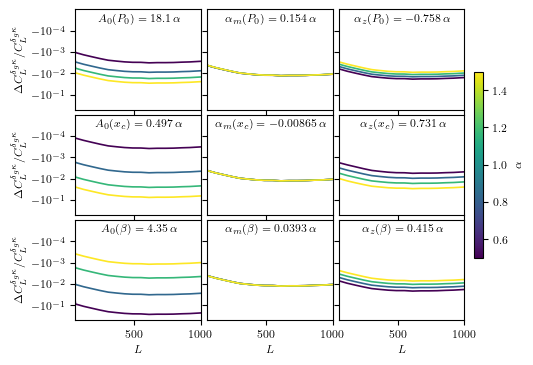

In [ ]:
import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(As_array)))

ells = experiment.biases['ells']
scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
[ax.set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$') for ax in axes[:,0]]

axes = axes.flatten()

titles = [r'$A_0(P_0) = 18.1 \, \alpha$', r'$\alpha_m(P_0) = 0.154 \, \alpha$', r'$\alpha_z(P_0) = -0.758 \, \alpha$',
r'$A_0(x_c) = 0.497 \, \alpha$', r'$\alpha_m(x_c) = -0.00865 \, \alpha$', r'$\alpha_z(x_c) = 0.731 \, \alpha$', 
r'$A_0(\beta) = 4.35 \, \alpha$', r'$\alpha_m(\beta) = 0.0393 \, \alpha$', r'$\alpha_z(\beta) = 0.415 \, \alpha$']

plot_breakdown = False
j=0
for exp_list_ in exp_list_perpanel:
    axes[j].axhline(0, color='k', lw=0.5, ls='-')    
    axes[j].text(500+40, -5e-5, titles[j], ha='center', va='center', fontsize=8, color='k', bbox=dict(facecolor='white', alpha=0))
    


    for color, experiment in zip(colors, exp_list_):
        for foreground in ['tsz']:            
            total = np.zeros(ells.shape, dtype='complex128')

            for linestyle, term in zip([':', '-.', '-'], ['1h', '2h', 'total']):
                if term == 'total':
                    if j==1:
                        label = r'{}'.format(float(As/1e-9))
                    else:
                        label = None
                    axes[j].plot(ells, ((scaling * total+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, label=label, lw=1.2)
                else:
                    # Extract contribution from this-halo term
                    bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                    # Accumulate to later plot the total
                    total += bias_contribution                
                    if plot_breakdown:
                        suffix='_withbreakdown'
                        axes[j].plot(ells, ((scaling * bias_contribution+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, lw=0.7)
                ax = plt.gca()
                ax.set_yscale('symlog', linthresh=1e-4)
        
    j+=1

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.05)

# Add a colorbar to the right of the plot with these values np.linspace(0.5, 1.5, 4)
import matplotlib as mpl
norm = mpl.colors.Normalize(vmin=0.5, vmax=1.5)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=axes, orientation='vertical', label=r'$\alpha$', shrink=0.6, pad=0.02)



plt.xlim([60, 1000])
plt.ylim([-5e-1,-1e-5])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'tsz_biases_to_cross_vs_tszparams.pdf', bbox_inches='tight', dpi=1000)

# Varying CIB

In [ ]:
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

base_cib_param_dict = {
    'alpha': 0.36, 
    'beta':1.75,
    'gamma':1.7,
    'delta':3.6,
    'Td_o':24.4,
    'logM_eff':12.6,
    'var':0.5,
    'L_o':8e-8
    }

base_cib_param_error_dict = {
    'alpha': 0.05, 
    'beta':0.06,
    'gamma':0.2,
    'delta':0.2,
    'Td_o':1.9,
    'logM_eff':0.1,
    'var':0.5/10,
    'L_o':8e-8/10
    }

exp_list = []

for key, entry in zip(base_cib_param_dict.keys(), base_cib_param_dict.values()):
    print(key)
    cib_par_ranges = np.arange(-2, 3) * base_cib_param_error_dict[key]
    for cib_par_shift in cib_par_ranges:
        filename = outdir + 'cib_dict_with_biases_cross_varyingcib_{}_scaling{}'.format(key, cib_par_shift)
        if os.path.exists(filename+'.pkl'):
            experiment = qest.load_dict_of_biases(filename+'.pkl')
        else:
            experiment = qest.experiment(lmax = 3000, massCut_Mvir=2e14, **ACT_properties, **fg_cleaning_dict)

            hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
            hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

            # Set the CIB params to the new value
            hm_calc.hcos.cib_params[key] = entry + cib_par_shift

            hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
            
            experiment.save_biases(output_filename=filename)
        
        exp_list.append(experiment)

# Calculate the signal clkg
pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
signal_Cl = hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.)

alpha
beta
gamma
delta
Td_o
logM_eff
var
L_o


In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/1.5 #8.77 #inches

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)

In [51]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:5], exp_list[5:10], exp_list[10:15], exp_list[15:20], exp_list[20:25], exp_list[25:30], exp_list[30:35], exp_list[35:40], exp_list[40:]]

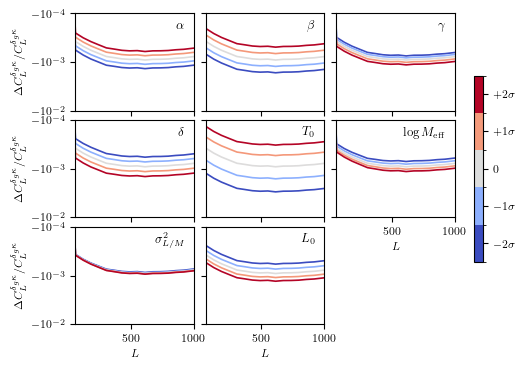

In [ ]:
import matplotlib.cm as cm
colors = cm.coolwarm(np.linspace(0, 1, 5))

try:
    ells = experiment.biases['ells']
except:
    ells = experiment['ells']
scaling = 0.5 * ells*(ells+1)

fig, axes = plt.subplots(3, 3, sharex=False, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
axes[1,2].set_xlabel(r'$L$')
[ax.set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$') for ax in axes[:,0]]

axes = axes.flatten()

titles = [r'$\alpha $', r'$\beta$', r'$\gamma $',
r'$\delta $', r'$T_0 $', r'$\log M_{\rm eff} $', 
r'$\sigma^2_{L/M} $', r'$L_0 $', r'']

j=0
for exp_list_ in exp_list_perpanel:
    axes[j].axhline(0, color='k', lw=0.5, ls='-')  
    axes[j].set_xlim([60, 1000])
    if j not in [5, 6, 7]:
        # Remove tick labels 
        axes[j].set_xticklabels([])

    axes[j].text(920, -1.8e-4, titles[j], ha='right', va='center', fontsize=9, color='k', bbox=dict(facecolor='white', alpha=0))
    
    for color, experiment in zip(colors, exp_list_):
        for foreground in ['cib']:            
            total = np.zeros(ells.shape, dtype='complex128')

            for linestyle, term in zip([':', '-.', '-'], ['1h', '2h', 'total']):
                if term == 'total':
                    axes[j].plot(ells, ((scaling * total+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, label=None, lw=1.2)
                else:
                    # Extract contribution from this-halo term
                    try:
                        bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                    except:
                        bias_contribution = experiment[foreground]['cross_w_gals'][term]
                    # Accumulate to later plot the total
                    total += bias_contribution                

                ax = plt.gca()
                ax.set_yscale('symlog', linthresh=1e-6)
        
    j+=1

# Delete the last subplot
fig.delaxes(axes[-1])

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.1, wspace=0.1)


# Define the boundaries for the color intervals
boundaries = np.linspace(0.5, 1.5, 6)  # 6 boundaries will create 5 intervals
# Create a Normalize object with these boundaries
norm = mpl.colors.BoundaryNorm(boundaries, ncolors=256)
# Create the ScalarMappable with the 'coolwarm' colormap and the BoundaryNorm
sm = plt.cm.ScalarMappable(cmap='coolwarm', norm=norm)
sm.set_array([])
# Create the colorbar
cbar = plt.colorbar(sm, ax=axes, orientation='vertical', shrink=0.6, pad=0.04)
# Set the ticks at the center of each color interval
tick_positions = (boundaries[:-1] + boundaries[1:]) / 2
cbar.set_ticks(tick_positions)
# Set the tick labels
cbar.set_ticklabels([r'$-2\sigma$', r'$-1\sigma$', r'$0$', r'$+1\sigma$', r'$+2\sigma$'])


plt.xlim([60, 1000])
plt.ylim([-1e-2,-1e-4])#plt.ylim([-1.2,1.2])

#plt.savefig(plots_dir+'cib_biases_to_cross_vs_cibparams.pdf', bbox_inches='tight', dpi=1000)

# With fg cleaning

In [ ]:
# Calculate the signal clkg
pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
signal_Cl = hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.)

In [89]:
SO_properties = {'nlev_t': np.array([52., 27., 5.8, 6.3, 15., 37.]),
                 'beam_size':np.array([7.4, 5.1, 2.2, 1.4, 1.0, 0.9]),
                 'freq_GHz': np.array([27.3, 41.7, 93., 143., 225.,278.])}

lmaxes = np.linspace(3000, 4500, 4).astype(int)

exp_list = []

for MV_ILC_bool, deproject_CIB, deproject_tSZ, label in zip([True, False, False], [False, True, False], [False, False, True], [r'MV ILC', r'CIB deproj. ILC', r'tSZ deproj. ILC']):
    fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}
    for lmax in lmaxes:
        print(lmax)
        experiment = qest.experiment(lmax = lmax, massCut_Mvir=2e14, **SO_properties, **fg_cleaning_dict)
        for which_bias in ['tsz', 'cib', 'mixed']:
            hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)
            hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.)

            if which_bias=='total' or which_bias=='tsz':
                hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
            if which_bias=='total' or which_bias=='cib':
                hm_calc.get_cib_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
            if which_bias=='total' or which_bias=='mixed':
                hm_calc.get_mixed_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
            
        exp_list.append(experiment)

# Calculate the signal clkg
pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
signal_Cl = hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, pgm_1h + pgm_2h, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.)

3000
3500
4000
4500
3000
3500
4000
4500
3000
3500
4000
4500


In [92]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:12], exp_list[12:16], exp_list[16:20], exp_list[20:24], exp_list[24:28], exp_list[28:32], exp_list[32:]]

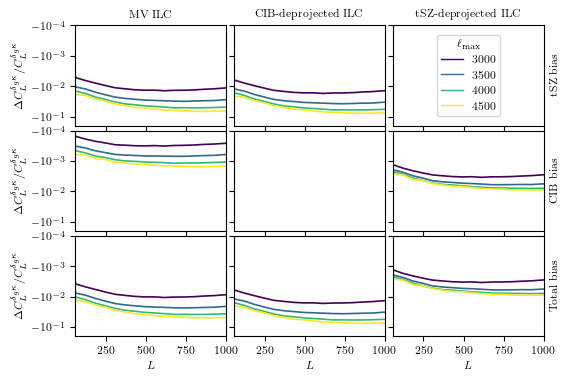

In [ ]:
import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(lmaxes)))

ells = experiment.biases['ells']
scaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)  

[ax.set_xlabel(r'$L$') for ax in axes[2, :]]
[ax.set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$') for ax in axes[:,0]]
[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'MV ILC', r'CIB-deprojected ILC', r'tSZ-deprojected ILC'])]

# Replace the colorbar with a legend to go in the third subplot
[axes[0,2].plot([],[], color=colors[i], lw=1, label=lmaxes.astype(int).astype(str)[i]) for i in range(len(lmaxes))]
axes[0,2].legend(title=r'$\ell_{\rm max}$', fontsize=8, title_fontsize=8, loc='center', ncols=1)

plot_breakdown = False

for exp_list_, fgcl_label, col in zip(exp_list_perpanel, 3*[r'MV ILC', r'CIB deproj. ILC', r'tSZ deproj. ILC'], 3*[0,1,2]): 
    for row, foreground in zip([0,1,2], ['tsz', 'cib', 'total']):
        axes[row,col].axhline(0, color='k', lw=0.5, ls='-')   
        for color, experiment in zip(colors, exp_list_):
            total = np.zeros(ells.shape, dtype='complex128')

            for linestyle, term in zip([':', '-.', '-'], ['1h', '2h', 'total']):
                if term == 'total':
                    axes[row,col].plot(ells, ((scaling * total+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, label=None, lw=1.2)
                else:
                    # Extract contribution from this-halo term
                    bias_contribution = experiment.biases[foreground]['cross_w_gals'][term]
                    # Accumulate to later plot the total
                    total += bias_contribution                
                    if plot_breakdown:
                        suffix='_withbreakdown'
                        axes[row,col].plot(ells, ((scaling * bias_contribution+signal_Cl)/signal_Cl - 1), color=color, ls=linestyle, lw=0.7)
                ax = plt.gca()
                ax.set_yscale('symlog', linthresh=1e-4)
        
    j+=1

# Set y label on right
[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'tSZ bias', r'CIB bias', r'Total bias'])]

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.05)

plt.xlim([60, 1000])
plt.ylim([-2e-1,-1e-4])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'all_biases_to_cross_vs_fgcleaning.pdf', bbox_inches='tight', dpi=1000)